# Our method against SGD and Adam: 2-task multi-MNIST

How does our method compare with SGD and Adam at their best step sizes? Our method runs with its one fixed
configuration, while SGD and Adam each get the step size that does best for them, on the fully connected network of
`../05_multi_mnist.ipynb`.

**Problem.** As in `../05_multi_mnist.ipynb`: each sample concatenates 2 independently drawn 14×14 MNIST training images
(per-pixel centered, one global scale), and each task's target is its own image's label. Every 1000 steps, one task
(chosen at random) gets a new random mapping from digits to labels, so each task changes about every 2000 steps. The
loss is the sum of each task's softmax cross-entropy.

**Network.** 392 inputs → 20 LTU hidden units → 20 linear outputs (2 groups of 10 logits), each layer with a bias,
fully connected: every hidden unit reads every input and feeds every output. Output weights and biases start at 0.

**Learners.**
- *SGD* and *Adam* (optax's, with $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$), in the standard setup:
  raw LTU outputs, input weights starting LeCun uniform, and the plain gradient of the loss (the LTU's backward pass
  uses the sigmoid's slope, as everywhere in this series). Each one's step size is swept over powers of 2 on 5 seeds,
  and the grid is extended until the best step size (highest mean online accuracy over the last 10% of training) has
  a worse one on both sides.
- *Our method*: Autostep ($\alpha_0 = 10^{-8}$, meta step-size 0.01, $\tau = 10^4$, each layer its own linear
  problem) with centered hidden units (each sends $h - m$, $m$ a running mean of its firing rate), a matching centered
  backward pass (each input weight's derivative is $\sigma'(z)x - \text{EMA}[\sigma'(z)x]$), and input weights
  starting at $U(-\alpha_0, \alpha_0)$. Not swept.
- *Our method + shadow weights + generate and test*: our method with both add-ons, in one run. Shadow weights: each
  hidden unit is paired with a random output (drawn per unit, so several units can share one) and a random shadow
  weight of $\pm 1$. In the backward pass a unit hears from every output through the output weights, except that the
  weight from its paired output counts as its shadow weight unless the real one is larger in magnitude; the forward
  pass is unchanged and the output weights keep their true gradients. Simple generate and test: every 100k steps, the
  hidden unit with the smallest mean $|$output weight$|$ starts over as a new unit (output weights 0, input weights
  $U(-\alpha_0, \alpha_0)$, step-sizes $\alpha_0$, zero Autostep traces, running means at their initial values, and a
  new random pairing and sign).

1000k steps. The main runs, at each optimizer's best step size, use 5 seeds for now (`N_SEEDS`); seed $s$ gives every
run, here and in `../05_multi_mnist.ipynb`, the same initial-weight draw, images and label changes. The sweeps use the
first 5 seeds.

**Hypothesis**, on the online accuracy (over both tasks) averaged over the last 10% of training, on paired seeds:
- **H1**: our method is at least as good as the better of SGD and Adam: at most 1 percentage point below it.

**Diagnostics**, fixed in advance, for the main runs: path purity and allocation over training, as in
`../05_multi_mnist.ipynb`. *Path purity* is the share of all input → hidden → output path weight (the product of $|w|$
along the path) that starts and ends in the same task: 1 when no path crosses tasks, 1/2 for even mixing.
*Allocation* is how evenly the hidden units are split between the tasks, counting each unit for the task whose
outputs it feeds most: 1 for 10 units each, 0 when all 20 feed one task.

Question 2, after the results, asks whether our network changes help SGD and Adam too.

In [1]:
from typing import Any, NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN = 20                        # 10 per task; every unit reads every input and feeds every output

# --- Our method (Autostep) ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (our network changes)
RESET_PERIOD = 100_000               # add-on: steps between resets of the unit with the smallest output weights

# --- SGD and Adam ---
SGD_EXPONENTS = range(-12, -1)       # first step sizes swept, 2**e; the grid is extended until the best is inside it
ADAM_EXPONENTS = range(-14, -3)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 5                          # seeds of the main runs (at most 30)
SWEEP_SEEDS = 5                      # seeds per step size in the sweeps
N_WINDOWS = 250                      # each window records its mean loss, accuracy, path purity and allocation

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

## Learner

In [4]:
LAYERS = ('w1', 'w2')
N_INPUTS, N_OUTPUTS = N_TASKS * N_PIXELS, N_TASKS * N_CLASSES

AUTOSTEP = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                      version='squared_inputs')
# SGD and Adam move the weights by -step size times a direction: the gradient, or Adam's (optax's defaults, b1 0.9,
# b2 0.999, eps 1e-8). The step size is an argument of learner_step, so that a sweep can vmap over it.
DIRECTIONS = {'SGD': optax.identity(), 'Adam': optax.scale_by_adam()}


class Learner(NamedTuple):
    w: dict                   # {'w1': (hidden, inputs + 1), 'w2': (outputs, hidden + 1)}; the last column is the bias
    opt: Any                  # the optimizer's state
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    pair: jax.Array           # each hidden unit's output for shadow weights ...
    sign: jax.Array           # ... and its +-1 shadow weight from that output


def init_learner(key, optimizer, ours):
    # `optimizer` is 'Autostep', 'SGD' or 'Adam'. Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) with our network
    # changes (`ours`), LeCun uniform otherwise. Both scale the same draw.
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / N_INPUTS)
    w1 = jax.random.uniform(key, (N_HIDDEN, N_INPUTS + 1), minval=-1.0, maxval=1.0) * bound
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros((N_OUTPUTS, N_HIDDEN + 1))}
    opt = AUTOSTEP.init(w) if optimizer == 'Autostep' else DIRECTIONS[optimizer].init(w)
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    pair = jax.random.randint(jax.random.fold_in(key, 1), (N_HIDDEN,), 0, N_OUTPUTS)
    sign = jax.random.rademacher(jax.random.fold_in(key, 2), (N_HIDDEN,), dtype=jnp.float32)
    return Learner(w, opt, jnp.full(N_HIDDEN, 0.5), jnp.zeros(w1.shape).at[:, -1].set(0.25), pair, sign)


def forward(w, x, learner, ours, shadow=False):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    z = w['w1'] @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w['w1'], axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    if not shadow:
        y_hat = w['w2'] @ jnp.append(h, 1.0)
    else:
        # Shadow weights: the outputs read h as usual, but h's gradient comes through a fixed matrix: the output
        # weights, except that the weight from each unit's paired output counts as its +-1 shadow weight unless the
        # real one is larger in magnitude. The last two terms cancel in value, and the output weights keep their true
        # gradient.
        units = jnp.arange(N_HIDDEN)
        paired = w['w2'][learner.pair, units]
        feedback = jax.lax.stop_gradient(
            w['w2'][:, :-1].at[learner.pair, units].set(jnp.where(jnp.abs(paired) > 1.0, paired, learner.sign)))
        y_hat = w['w2'] @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, labels, optimizer, step_size, ours, shadow=False):
    # One online update on the summed softmax cross-entropy of every task: Autostep's, or -step_size times SGD's or
    # Adam's direction. Returns the new learner, the loss and the fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, ours, shadow)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    if optimizer == 'Autostep':
        updates, opt = AUTOSTEP.update((grads, None, source_values), learner.opt, learner.w)
    else:
        direction, opt = DIRECTIONS[optimizer].update(grads, learner.opt)
        updates = jax.tree.map(lambda d: -step_size * d, direction)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    learner = learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope)
    return learner, loss, jnp.mean(logits.argmax(-1) == labels)

## Training

In [5]:
WINDOW = NUM_STEPS // N_WINDOWS      # steps per window
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def path_purity(w):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task. Biases are left out.
    reads = jnp.abs(w['w1'][:, :-1]).reshape(N_HIDDEN, N_TASKS, N_PIXELS).sum(-1)      # (unit, task)
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, N_HIDDEN).sum(1).T    # (unit, task)
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(-1) * feeds.sum(-1)), 1e-30)


def allocation(w):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most: 1 when every task has the same number, 0 when all units feed one task.
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, N_HIDDEN).sum(1)      # (task, unit)
    largest = jnp.max(jnp.bincount(feeds.argmax(0), length=N_TASKS)) / N_HIDDEN
    return (1 - largest) / (1 - 1 / N_TASKS)


def generate_and_test(learner, key):
    # The hidden unit with the smallest mean |output weight| starts over as a new unit: its weights, step-sizes,
    # Autostep traces, running means, shadow pairing and sign are set to those of a freshly initialized network of our
    # method (output weights 0, input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE)).
    unit = jnp.arange(N_HIDDEN) == jnp.argmin(jnp.abs(learner.w['w2'][:, :-1]).mean(0))
    fresh = init_learner(key, 'Autostep', ours=True)
    parts = {'w1': unit[:, None], 'w2': jnp.append(unit, False)[None, :]}     # the unit's row of w1, column of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    return learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(unit, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(unit[:, None], fresh.hidden_slope, learner.hidden_slope),
        pair=jnp.where(unit, fresh.pair, learner.pair), sign=jnp.where(unit, fresh.sign, learner.sign))


def train(key, stream, step_size, optimizer, ours, add_ons=False):
    # Step 1 on its own, then NUM_STEPS online steps in windows. With `add_ons` (our method only), the hidden units
    # learn through shadow weights, and generate and test runs at the end of every window that ends on a multiple of
    # RESET_PERIOD. Returns the mean loss and accuracy of every window, and the path purity and allocation at its end.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, optimizer, step_size, ours, add_ons)
        return (learner, stream), (loss, accuracy)

    def window(carry, index):
        (learner, stream), (loss, accuracy) = jax.lax.scan(one_step, carry, length=WINDOW)
        if add_ons:
            reset = generate_and_test(learner, jax.random.fold_in(key, index))
            due = (index + 1) * WINDOW % RESET_PERIOD == 0
            learner = jax.tree.map(lambda new, old: jnp.where(due, new, old), reset, learner)
        w = learner.w
        return (learner, stream), {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'purity': path_purity(w),
                                   'allocation': allocation(w)}

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, optimizer, ours), x, labels, optimizer, step_size, ours, add_ons)[0]
    return jax.lax.scan(window, (learner, stream), jnp.arange(N_WINDOWS))[1]


def seeds(n):
    # The first n seeds' init keys and streams, taken from 30 so that seed s is the same in every notebook. Seed s uses
    # init key s and stream s in every run, so runs are paired.
    keys = jax.random.split(jax.random.PRNGKey(0), 30)[:n]
    return keys, jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), 30)[:n])


def run(optimizer, ours, step_sizes=(0.0,), n_seeds=N_SEEDS, add_ons=False):
    # Trains `optimizer` (with our network changes if `ours`) at every step size in `step_sizes` (Autostep ignores it)
    # on the first `n_seeds` seeds, all vmapped into one scan. Returns one record per step size: loss, accuracy, purity
    # and allocation (seed, window).
    keys, streams = seeds(n_seeds)
    tile = lambda a: jnp.tile(a, (len(step_sizes),) + (1,) * (a.ndim - 1))
    step_size = jnp.repeat(jnp.asarray(step_sizes, dtype=jnp.float32), n_seeds)
    train_all = jax.vmap(lambda key, stream, s: train(key, stream, s, optimizer, ours, add_ons))
    records = jax.tree.map(np.asarray, jax.jit(train_all)(tile(keys), jax.tree.map(tile, streams), step_size))
    return [jax.tree.map(lambda a: a[i * n_seeds:(i + 1) * n_seeds], records) for i in range(len(step_sizes))]


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def best_exponent(sweep_records):
    # The step size 2**e with the highest mean accuracy over the last FINAL_FRACTION: its e.
    return max(sweep_records, key=lambda e: final_accuracy(sweep_records[e]).mean())


def sweep(optimizer, ours, exponents):
    # Trains `optimizer` at step sizes 2**e for every e in `exponents`, on SWEEP_SEEDS seeds each. While the best step
    # size is at an end of the grid, the next power of 2 past that end is added. Returns {e: records} for every e tried.
    records, new = {}, list(exponents)
    while new:
        records.update(zip(new, run(optimizer, ours, 2.0 ** np.array(new), SWEEP_SEEDS)))
        best = best_exponent(records)
        new = [best - 1] if best == min(records) else [best + 1] if best == max(records) else []
    return dict(sorted(records.items()))

## Results

SGD: best step size 2^-2, online accuracy 77.47%
Adam: best step size 2^-6, online accuracy 75.08%


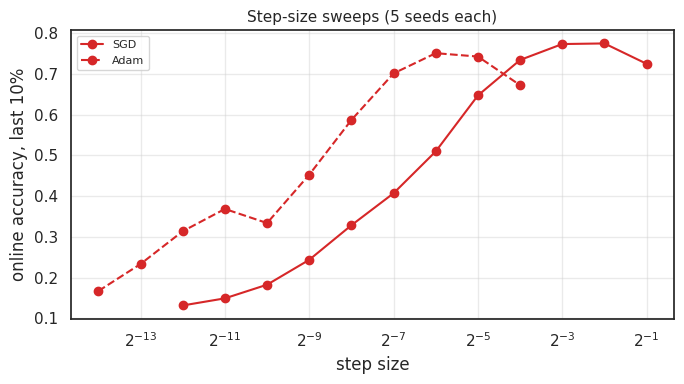

In [6]:
window_ends = np.arange(1, N_WINDOWS + 1) * WINDOW


def plot_sweeps(sweeps, styles):
    # Online accuracy over the last FINAL_FRACTION of training (mean over seeds) against the step size, for every value
    # of every sweep in `sweeps`, drawn in styles[label] = (color, line style). Prints each sweep's best step size.
    fig, ax = plt.subplots(figsize=(7, 4))
    for label, records in sweeps.items():
        color, ls = styles[label]
        ax.plot(2.0 ** np.array(list(records)), [final_accuracy(r).mean() for r in records.values()], color=color,
                ls=ls, marker='o', lw=1.5, label=label)
        e = best_exponent(records)
        print(f'{label}: best step size 2^{e}, online accuracy {final_accuracy(records[e]).mean():.2%}')
    ax.set_xscale('log', base=2)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
    ax.set_xlabel('step size')
    ax.set_ylabel('online accuracy, last 10%')
    ax.set_title(f'Step-size sweeps ({SWEEP_SEEDS} seeds each)', fontsize=11)
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


sweeps = {'SGD': sweep('SGD', False, SGD_EXPONENTS), 'Adam': sweep('Adam', False, ADAM_EXPONENTS)}
plot_sweeps(sweeps, {'SGD': ('tab:red', '-'), 'Adam': ('tab:red', '--')})

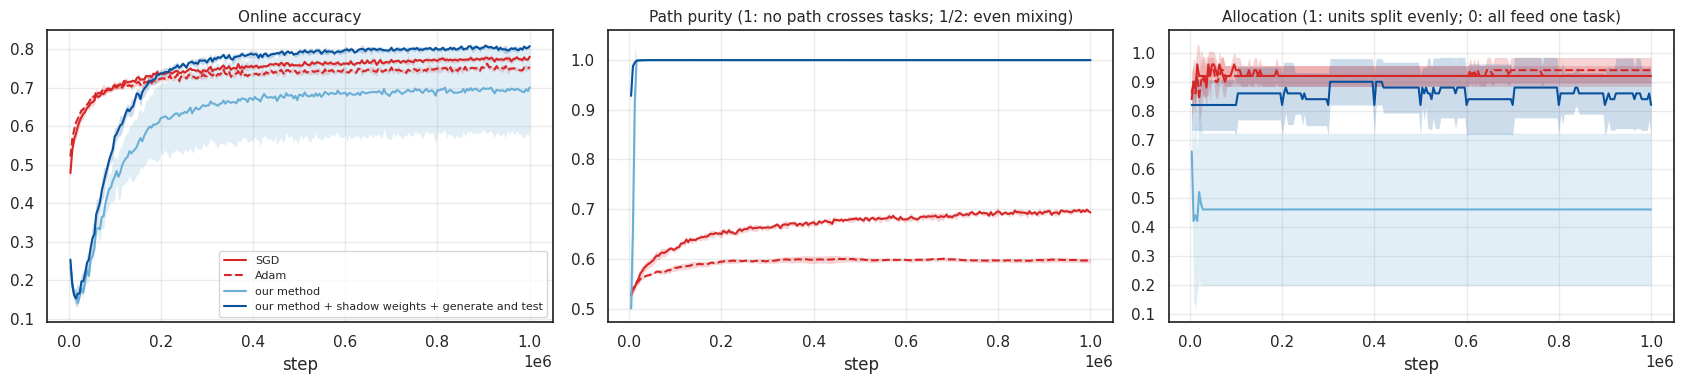

SGD                                               online accuracy 77.47%
Adam                                              online accuracy 75.08%
our method                                        online accuracy 69.41%
our method + shadow weights + generate and test   online accuracy 80.23%
H1, our method vs SGD: -8.1 points (± 11.4): failed


In [7]:
def plot_runs(runs, colors, dashed=()):
    # Accuracy, path purity and allocation over training for each run in `runs` (mean +- 2 SE over seeds), drawn in
    # `colors[label]`, and dashed for the labels in `dashed`.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (key, title) in zip(axes, [('accuracy', 'Online accuracy'),
                                       ('purity', 'Path purity (1: no path crosses tasks; 1/2: even mixing)'),
                                       ('allocation', 'Allocation (1: units split evenly; 0: all feed one task)')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(window_ends, mean, color=colors[label], ls='--' if label in dashed else '-', lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(title, fontsize=11)
        ax.grid(alpha=0.4)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def report(runs, tests):
    # Prints every run's accuracy, then for each test (name, label, reference, claim) the per-seed gap of `label` to
    # `reference` (mean and 2 SE over paired seeds), and whether the claim held: 'within' ACCURACY_TOLERANCE of it, or
    # more than that 'below' it.
    width = max(map(len, runs))
    for label, res in runs.items():
        print(f'{label:<{width}}   online accuracy {final_accuracy(res).mean():.2%}')
    for name, label, reference, claim in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        ok = g.mean() >= -ACCURACY_TOLERANCE if claim == 'within' else g.mean() < -ACCURACY_TOLERANCE
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}): {"held" if ok else "failed"}')


runs = {'SGD': run('SGD', False, [2.0 ** best_exponent(sweeps['SGD'])])[0],
        'Adam': run('Adam', False, [2.0 ** best_exponent(sweeps['Adam'])])[0],
        'our method': run('Autostep', True)[0],
        'our method + shadow weights + generate and test': run('Autostep', True, add_ons=True)[0]}
plot_runs(runs, {'SGD': 'tab:red', 'Adam': 'tab:red', 'our method': '#6baed6',
                 'our method + shadow weights + generate and test': '#08519c'}, dashed=['Adam'])
better = max(['SGD', 'Adam'], key=lambda label: final_accuracy(runs[label]).mean())
report(runs, [('H1', 'our method', better, 'within')])

- **Sweeps.** SGD does best at step size $2^{-2}$, with 77.5% online accuracy over the last 10% of training; $2^{-3}$
  is about as good (about 77.3%) and $2^{-1}$ worse (about 72%). Adam does best at $2^{-6}$, with 75.1%, against about
  70% at $2^{-7}$ and 74% at $2^{-5}$. SGD's grid was extended by one value ($2^{-1}$); Adam's best was inside its first
  grid.
- **H1 failed.** Our method reaches 69.4% against 77.5% for SGD, the better of the two (Adam 75.1%): −8.1 points
  (± 11.4, 2 SE over paired seeds). The gap comes from 2 of the 5 seeds, where our method splits the units 18/2 and
  19/1 between the tasks and reaches 58.3% and 50.1%. In the other 3 (splits 12/8, 12/8 and 16/4) it reaches 80.5%,
  80.0% and 78.2%, above SGD on the same seeds (77.4%, 76.9% and 78.1%). These 5 seeds are among our method's worst:
  its runs here are identical to the first 5 of `../05_multi_mnist.ipynb`, whose 30 seeds average 75.6%, still about 2
  points below SGD's mean here.
- **Add-ons.** With shadow weights and generate and test, our method reaches 80.2%, 2.8 points above SGD (no
  hypothesis was set for this run). It is slower at first: SGD and Adam are at about 70% by 50k steps, and it passes
  them only at about 200k steps.
- **Diagnostics.** SGD and Adam mix the tasks but split the units evenly: path purity ends at about 0.70 (SGD) and
  0.60 (Adam), and allocation stays at about 0.9. Our method never mixes them (purity 1 within about 20k steps) but
  splits the units unevenly (allocation 0.46 on these seeds, fixed from about 20k steps). With the add-ons, purity is
  1 and allocation about 0.85.
- SGD's and Adam's main runs use the same 5 seeds as their sweeps, so they are the sweeps' best runs; picking the best
  of 12 (SGD) or 11 (Adam) step sizes on these seeds favours them a little.

## Question 2: do our network changes help SGD and Adam too?

A separate experiment: SGD and Adam on our method's network, that is with centered hidden units, the centered backward
pass, and input weights starting at $U(-10^{-8}, 10^{-8})$ (output weights and biases still start at 0). Their step
sizes are swept again in the same way (powers of 2 on 5 seeds, extended until the best has a worse one on both sides).
Each, at its new best step size, is compared with itself in the standard setup at its best step size (Question 1's
main runs), on paired seeds.

**H2**: for each optimizer, the changes raise its online accuracy over the last 10% of training by more than 1
percentage point.

SGD: best step size 2^-2, online accuracy 77.47%
Adam: best step size 2^-6, online accuracy 75.08%
SGD, our changes: best step size 2^-2, online accuracy 80.31%
Adam, our changes: best step size 2^-6, online accuracy 78.49%


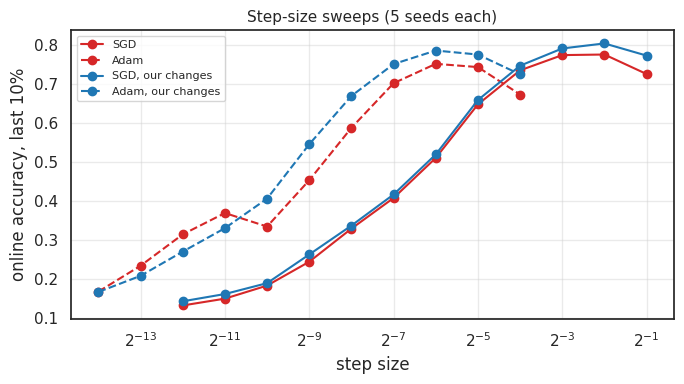

SGD                 online accuracy 77.47%
Adam                online accuracy 75.08%
SGD, our changes    online accuracy 80.31%
Adam, our changes   online accuracy 78.49%
H2 (SGD), SGD vs SGD, our changes: -2.8 points (± 0.5): held
H2 (Adam), Adam vs Adam, our changes: -3.4 points (± 0.2): held


In [8]:
changed_sweeps = {'SGD, our changes': sweep('SGD', True, SGD_EXPONENTS),
                  'Adam, our changes': sweep('Adam', True, ADAM_EXPONENTS)}
plot_sweeps({**sweeps, **changed_sweeps},
            {'SGD': ('tab:red', '-'), 'Adam': ('tab:red', '--'), 'SGD, our changes': ('tab:blue', '-'),
             'Adam, our changes': ('tab:blue', '--')})
changed_runs = {label: run(label.split(',')[0], True, [2.0 ** best_exponent(records)])[0]
                for label, records in changed_sweeps.items()}
report({'SGD': runs['SGD'], 'Adam': runs['Adam'], **changed_runs},
       [('H2 (SGD)', 'SGD', 'SGD, our changes', 'below'), ('H2 (Adam)', 'Adam', 'Adam, our changes', 'below')])

- **Sweeps.** The changes leave the best step sizes where they were: $2^{-2}$ for SGD (80.3%) and $2^{-6}$ for Adam
  (78.5%). For SGD they matter only at the largest step sizes ($2^{-4}$ and up; the curves coincide below). For Adam
  they help at every step size from $2^{-10}$ up and cost a few points below it.
- **H2 held for both.** SGD: 80.3% against 77.5%, +2.8 points (± 0.5, 2 SE over paired seeds). Adam: 78.5% against
  75.1%, +3.4 points (± 0.2).
- With the changes and no add-ons, SGD (80.3%) is level with our method with both add-ons (80.2%, same seeds) and with
  our method on the ideal connectivity in `../05_multi_mnist.ipynb` (80.6%, 30 seeds). No diagnostics were fixed in
  advance for this question, so it is not shown whether the gain comes from purity or allocation.
- As in Question 1, the main runs reuse the sweeps' 5 seeds, which favours the runs with the changes and the standard
  runs alike.